In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

**5.22 Cài đặt ID3 trong Python**

*check file ID3.py trong folder model*

In [2]:
from model.ID3 import ID3
import pprint
data = pd.read_csv("data/id3_example.csv", encoding="utf-8")
# data.head()

features = list(data.columns[1:-1])
target = "Mua máy tính"

model = ID3()
tree_dict = model.build_tree(data, features, target)
pprint.pprint(tree_dict)

# test samples
test_samples = pd.DataFrame([
    {"Tuổi": "Trẻ",        "Thu nhập": "Thấp",       "Sinh viên": "Không", "Đánh giá tín dụng": "Tốt"},
    {"Tuổi": "Trẻ",        "Thu nhập": "Trung bình", "Sinh viên": "Có",    "Đánh giá tín dụng": "Xuất sắc"},
    {"Tuổi": "Trung niên", "Thu nhập": "Thấp",       "Sinh viên": "Không", "Đánh giá tín dụng": "Xuất sắc"},
    {"Tuổi": "Già",        "Thu nhập": "Cao",        "Sinh viên": "Không", "Đánh giá tín dụng": "Tốt"},
    {"Tuổi": "Già",        "Thu nhập": "Cao",        "Sinh viên": "Có",    "Đánh giá tín dụng": "Xuất sắc"}
])

test_samples["Dự đoán Mua máy tính"] = test_samples.apply(lambda row: model.predict(row), axis=1)
display(test_samples)

{'Tuổi': {'Già': {'Đánh giá tín dụng': {'Tốt': 'Có', 'Xuất sắc': 'Không'}},
          'Trung niên': 'Có',
          'Trẻ': {'Sinh viên': {'Có': 'Có', 'Không': 'Không'}}}}


,Tuổi,Thu nhập,Sinh viên,Đánh giá tín dụng,Dự đoán Mua máy tính
0,Trẻ,Thấp,Không,Tốt,Không
1,Trẻ,Trung bình,Có,Xuất sắc,Có
2,Trung niên,Thấp,Không,Xuất sắc,Có
3,Già,Cao,Không,Tốt,Có
4,Già,Cao,Có,Xuất sắc,Không


**5.23 CART với scikit-learn**

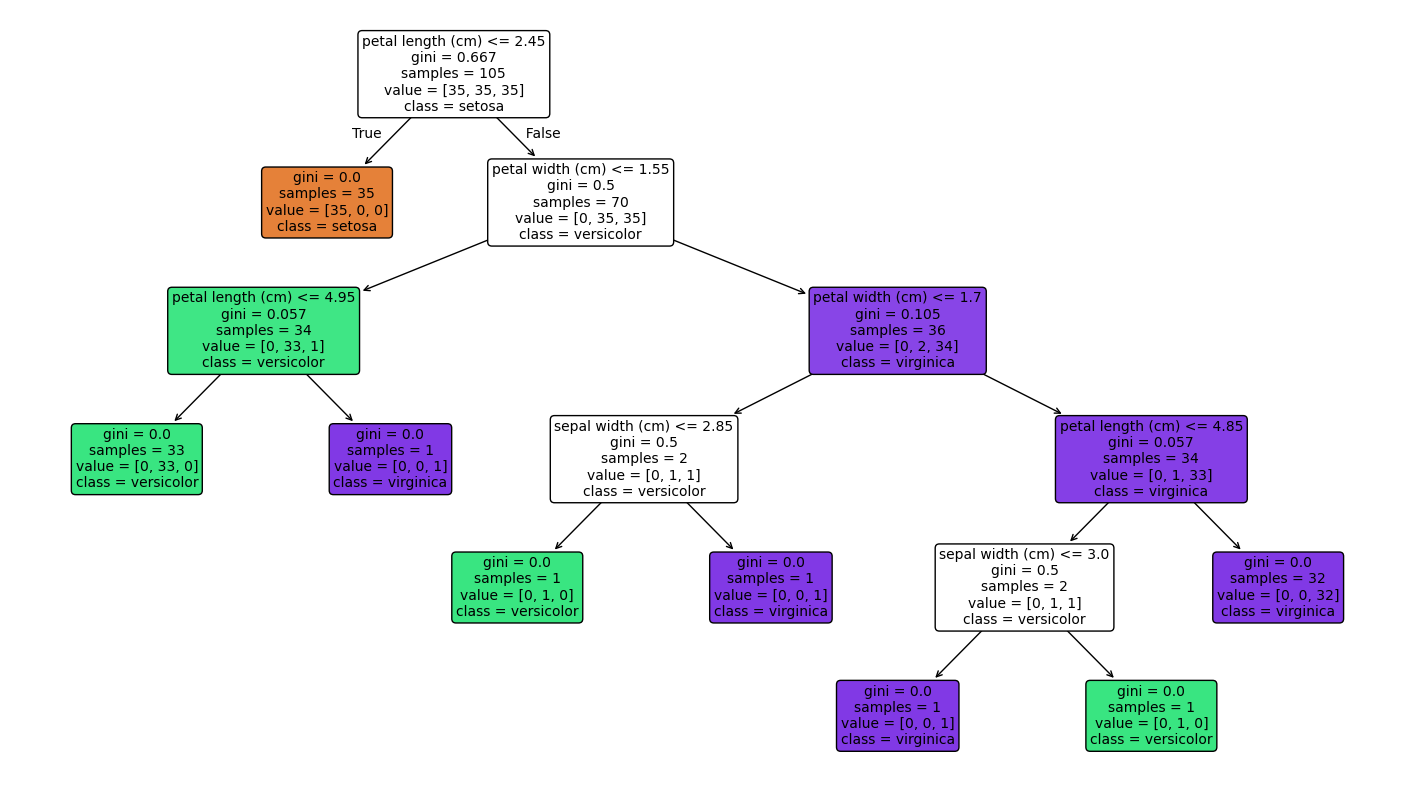

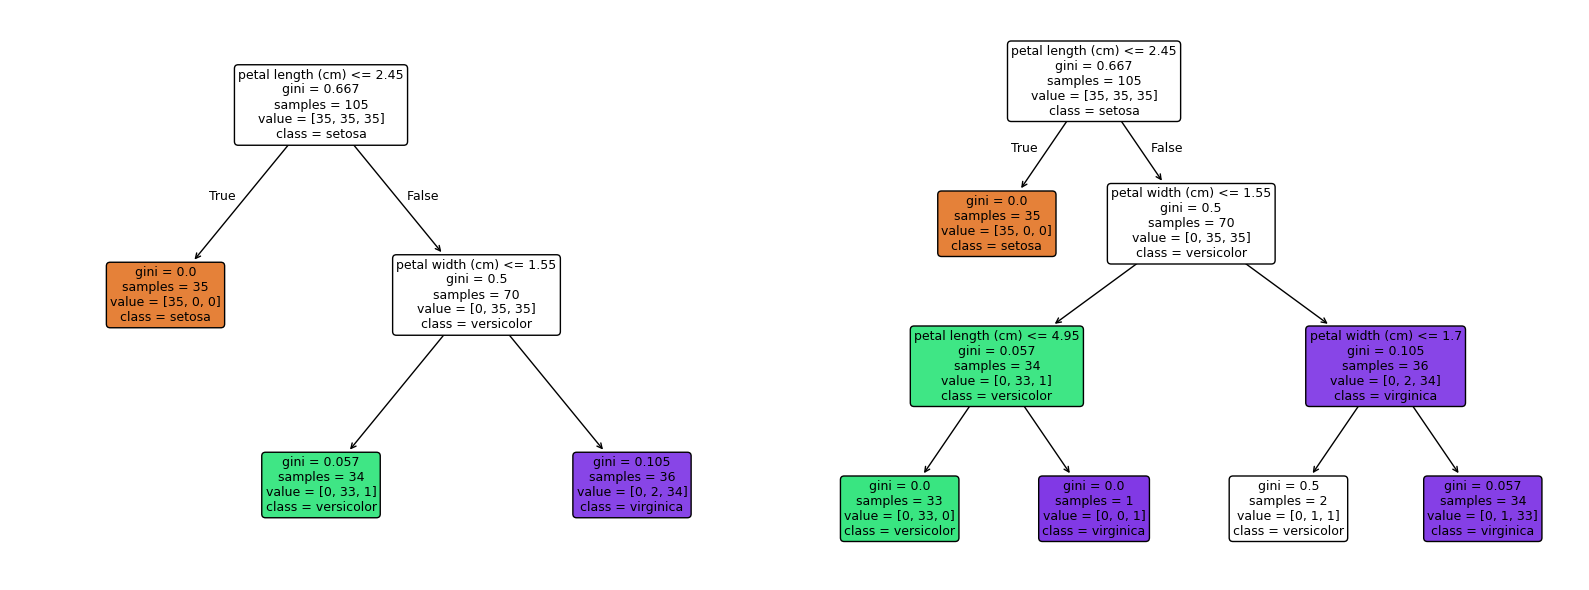

=== BẢNG SO SÁNH ĐỘ CHÍNH XÁC TRÊN TẬP TRAIN / TEST ===


,max_depth thiết lập,Độ sâu thực tế,Số nút lá (Leaves),Train Accuracy (%),Test Accuracy (%),Chênh lệch (Train - Test)
0,Không giới hạn,5,8,100.00,93.33,6.67
1,2,2,3,97.14,88.89,8.25
2,3,3,5,98.10,97.78,0.32


In [5]:
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)
model = DecisionTreeClassifier(criterion="gini", max_depth=None, random_state=42)
model.fit(X_train, y_train)
# visualization
plt.figure(figsize=(18, 10))
plot_tree(
    model,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.show()

# prune tree by max_depth
depths = [None, 2, 3]
results = []
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for idx, d in enumerate(depths):
    model = DecisionTreeClassifier(criterion='gini', max_depth=d, random_state=42)
    model.fit(X_train, y_train)
    
    train_acc = accuracy_score(y_train, model.predict(X_train))
    test_acc = accuracy_score(y_test, model.predict(X_test))
    
    results.append({
        "max_depth thiết lập": "Không giới hạn" if d is None else str(d),
        "Độ sâu thực tế": model.get_depth(),
        "Số nút lá (Leaves)": model.get_n_leaves(),
        "Train Accuracy (%)": round(train_acc * 100, 2),
        "Test Accuracy (%)": round(test_acc * 100, 2),
        "Chênh lệch (Train - Test)": round((train_acc - test_acc) * 100, 2)
    })
    
    if d in [2, 3]:
        ax = axes[0] if d == 2 else axes[1]
        plot_tree(
            model,
            feature_names=iris.feature_names,
            class_names=iris.target_names,
            filled=True,
            rounded=True,
            ax=ax,
            fontsize=9
        )

plt.tight_layout()
plt.show()

# Hiển thị bảng tổng hợp kết quả so sánh
df_results = pd.DataFrame(results)
print("=== BẢNG SO SÁNH ĐỘ CHÍNH XÁC TRÊN TẬP TRAIN / TEST ===")
display(df_results)

**5.24 CART Hồi quy**

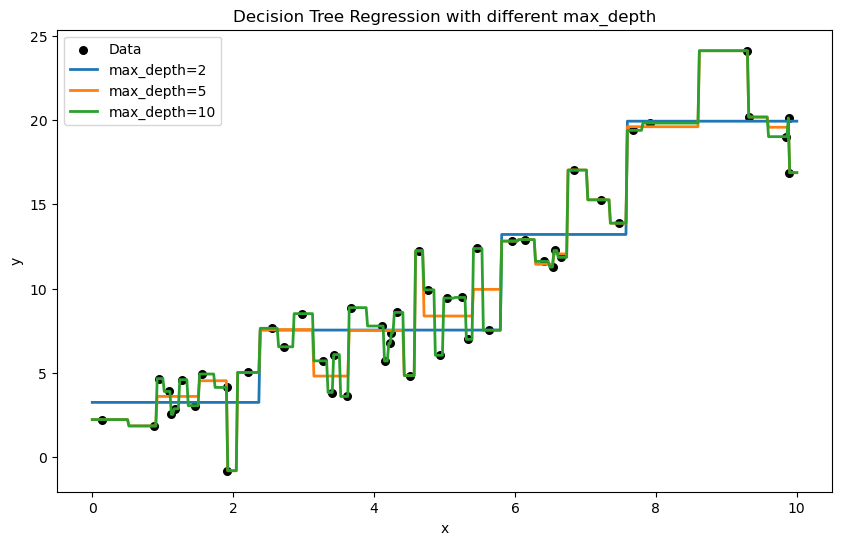

In [7]:
from sklearn.tree import DecisionTreeRegressor

# initialize data
n = 50
X = np.sort(np.random.uniform(0, 10, n)).reshape(-1, 1)
noise = np.random.normal(0, 2.0, n)
y = 2 * X.ravel() + np.sin(X.ravel()) + noise

depths = [2, 5, 10]
X_plot = np.linspace(0, 10, 500).reshape(-1, 1)

plt.figure(figsize=(10, 6))
plt.scatter(X, y, color="black", s=30, label="Data")

colors = ["tab:blue", "tab:orange", "tab:green"]
for d, c in zip(depths, colors):
    model = DecisionTreeRegressor(max_depth=d, random_state=42)
    model.fit(X, y)
    plt.plot(X_plot, model.predict(X_plot), color=c, lw=2, label=f"max_depth={d}")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Decision Tree Regression with different max_depth")
plt.legend()
plt.show()

với mô hình sâu nhất (max_depth = 10), cây của nó có thể chứa tới 2^10 lá, lớn hơn rất nhiều so với số lượng điểm dữ liệu, khi nó mô hình có thể plot từng điểm
với từng nút lá -> sinh ra hiện tượng overfitting